<a href="https://colab.research.google.com/github/Israel-Garcilazo/-Tesis-MOOP-y-algoritmos-evolutivos/blob/Actividades/Vectores_Dominados_V3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Actividad 1**
* Escribir un algoritmo que dados n vectores en $\mathbb{R}^n
$, simulando ser los valores de F, encuentre los vectores asociados a puntos no dominados.



A continuación se va a mostrar un breve código diseñado en Python donde se resuelve el problema planetado.
Cabe aclarar que dicho programa pide ingresar como *imput* el número de vectores [n] y la dimensión de los vectores [k], posteriormente genera de forma aleatoria los [n] vectores e imprime los vectores generados y los no dominados.

Para este caso, probaremos con $n = 1000$, lo que generará mil vectores aleatorios, los hará pasar por la función para obtener las imágenes y los cllasificará por dominado y no dominado.

Ingrese [n]: 1000
Vectores generados aleatoriamente: [[3, 3], [7, 3], [0, 9], [4, 3], [5, 5], [8, 1], [3, 4], [8, 1], [3, 10], [8, 4], [7, 5], [1, 8], [3, 0], [7, 6], [9, 6], [1, 8], [9, 6], [10, 3], [9, 4], [3, 1], [8, 4], [6, 3], [3, 8], [5, 5], [2, 9], [2, 0], [7, 7], [2, 5], [8, 5], [7, 5], [6, 2], [5, 7], [5, 1], [0, 8], [4, 1], [1, 10], [8, 10], [10, 1], [10, 10], [6, 0], [3, 8], [7, 1], [6, 10], [0, 10], [9, 10], [9, 0], [3, 9], [5, 2], [4, 5], [5, 8], [1, 5], [5, 4], [3, 4], [8, 8], [1, 5], [4, 9], [1, 2], [0, 10], [9, 0], [4, 5], [4, 4], [4, 8], [4, 7], [2, 9], [7, 9], [8, 0], [0, 9], [6, 2], [9, 4], [0, 7], [3, 7], [3, 6], [1, 3], [5, 1], [9, 10], [3, 6], [8, 3], [3, 10], [8, 6], [7, 1], [8, 8], [4, 6], [1, 8], [0, 7], [8, 9], [2, 9], [7, 6], [5, 5], [10, 7], [6, 1], [4, 2], [9, 6], [9, 10], [7, 6], [3, 1], [8, 4], [10, 5], [1, 4], [5, 3], [9, 4], [0, 3], [8, 4], [1, 5], [1, 6], [2, 7], [9, 7], [6, 9], [2, 8], [0, 1], [9, 9], [7, 2], [7, 4], [0, 2], [5, 3], [7, 9], [0, 0], [2

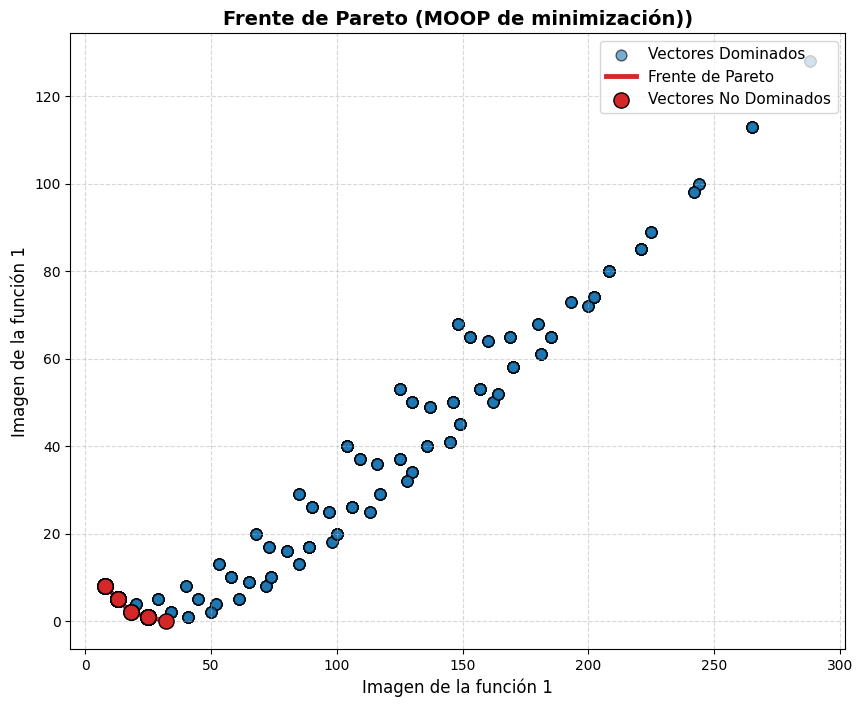

In [19]:
#Importamos la función clave de Python que va a ayudar a generar la aleatoriedad y la visualización.
import random
import matplotlib.pyplot as plt

#Definimos las variables leyendo n y k desde el input
n = int(input("Ingrese [n]: "))
k = 2

# Generamos los puntos en el espacio de las variables (X)
X = [[random.randint(0, 10) for _ in range(k)] for _ in range(n)]

# Con un ciclo for, evaluamos cada vector de los generados en el paso anterior para obtener las imágenes
F = [[(x[0]+2)**2 + (x[1]+2)**2, (x[0]-2)**2 + (x[1]-2)**2] for x in X]

# Criterio de ordenamiento para definir cuáles vectores están o no dominados.
P = [v for i, v in enumerate(F) if not any(i != j and all(a <= b for a, b in zip(y, v)) and any(a < b for a, b in zip(y, v)) for j, y in enumerate(F))]

# Separamos las imágenes que están dominadas
D = [v for v in F if v not in P]

# Se imprimen todos los vectores generados y los no dominados.
print("Vectores generados aleatoriamente:", X)
print("Imágenes de los vectores aleatorios:", F)
print("Frente de Pareto construido de los vectores no dominados:", P)
print("Vectores dominados:", D)


# Lo siguiente es una plantilla adaptada, hallada en las guías de Python. Sirve para graficar frentes de Pareto.
plt.figure(figsize=(10, 8))

if D:
    d_x = [d[0] for d in D]
    d_y = [d[1] for d in D]
    plt.scatter(d_x, d_y, color='#1f77b4', s=60, alpha=0.6, edgecolors='black', label='Vectores Dominados')

if P:
    P_sorted = sorted(P, key=lambda val: val[0])
    p_x = [p[0] for p in P_sorted]
    p_y = [p[1] for p in P_sorted]
    plt.plot(p_x, p_y, color='#d62728', linestyle='-', linewidth=3.5, label='Frente de Pareto', zorder=3)
    plt.scatter(p_x, p_y, color='#d62728', s=120, edgecolors='black', zorder=4, label='Vectores No Dominados')
plt.title('Frente de Pareto (MOOP de minimización))', fontsize=14, fontweight='bold')
plt.xlabel('Imagen de la función 1', fontsize=12)
plt.ylabel('Imagen de la función 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper right')

plt.show()

* ¿Cómo se comporta el algoritmo conforme crece [n]?

El algoritmo tiene que comparar $n$ vectores con cada uno de los $n-1$ vectores, resviando en $k$ componentes. Esto significa que el orden de complejidad temporal, tambien llamado *costo*, es de $O(kn²)$, lo que significa que, incluso aunque $k$ sea constante, el algoritmo debe de hacer una trabajo exponencial por cada vector que se agregue, dejándonos con que el crecimiento del trabajo del algoritmo se puede visualizar como:

$n → n²$

$2n → 4n²$

$10n → 100n²$

$100n → 1000n²$

* ¿Será posible construir un algoritmo que cumpla el mismo proposito, pero que tenga un orden menor a $O(kn²)$?

La respuesta es **sí** y se puede separar en dos casos:


1.   Si $k=2$

Para este caso, lo que debería de hacerse es primero ordenar los vectores de menor a mayor, basándose únicamente en la primera dimensión, lo que le cuesta a la máquina un trabajo de $O(n log n)$. Luego se aplicaría un ciclo lineal a la segunda dimensión para poder analizar y guardar el mínimo historico, y al último descartar todos aquellos valores no dominados. Dejando así un costo computacional de $O(n log n)$, muy inferior al costo $O(nk²)$ que se tenía originalmente.    

2.   Si k>2

Existen algoritmos para estos casos que lo que hacen es dividir y trabajar en dos de forma recursiva sobre el número de vectores dados. Con cada mitad se trabaja de forma similar a la anterior, que es buscar una forma de ordenar los datos de menor a mayor para luego simplemente escoger el mínimo global y descartar. De esta forma se puede obtener un costo computucional de $O(nlog^{k-1} n)$ u $O(n(logn)^{k-2})$, lo que sigue siendo aún menor a el costo $O(nk²)$ que se tenía originalmente.